# Growth-rate analysis by COVID-19 wave
**Question:** Does the per-capita weekly growth rate decrease approximately linearly with cumulative cases within each wave, as the logistic model predicts?

The growth proxy is weekly new cases divided by cumulative cases since wave start. It is noisy and not the instantaneous derivative, but it gives a useful descriptive comparison. We report OLS slopes and R², without treating them as causal evidence.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import linregress

ROOT=Path.cwd()

if not (ROOT/"data/processed/us_covid_all_waves.csv").exists(): ROOT=ROOT.parent
DATA=ROOT/"data/processed/us_covid_all_waves.csv"

df=pd.read_csv(DATA,parse_dates=["week_ending"])
required={"wave","new_cases","cumulative_cases_in_wave","week_ending"}
missing=required-set(df.columns)

if missing: raise ValueError(f"Missing columns: {missing}")

df=df.sort_values(["wave","week_ending"]).copy()
df["growth_proxy"]=df["new_cases"]/df["cumulative_cases_in_wave"].replace(0,np.nan)
df=df.replace([np.inf,-np.inf],np.nan).dropna(subset=["growth_proxy"])
df=df[df["cumulative_cases_in_wave"]>0]
df.head()

,week_ending,total_cases,total_deaths,new_cases,new_deaths,week,cases_reported,cases_smoothed,wave,week_number,elapsed_weeks,cumulative_cases_in_wave,growth_proxy
0,2020-01-26,7,0,7.0,0.0,0,True,4.500000,1,0,0,7.0,1.000000
1,2020-02-02,9,0,2.0,0.0,1,True,6.666667,1,1,1,9.0,0.222222
2,2020-02-09,20,0,11.0,0.0,2,True,6.000000,1,2,2,20.0,0.550000
3,2020-02-16,24,0,4.0,0.0,3,True,8.250000,1,3,3,24.0,0.166667
4,2020-02-23,40,0,16.0,0.0,4,True,16.000000,1,4,4,40.0,0.400000


## 1. Wave-wise scatterplots and linear fits

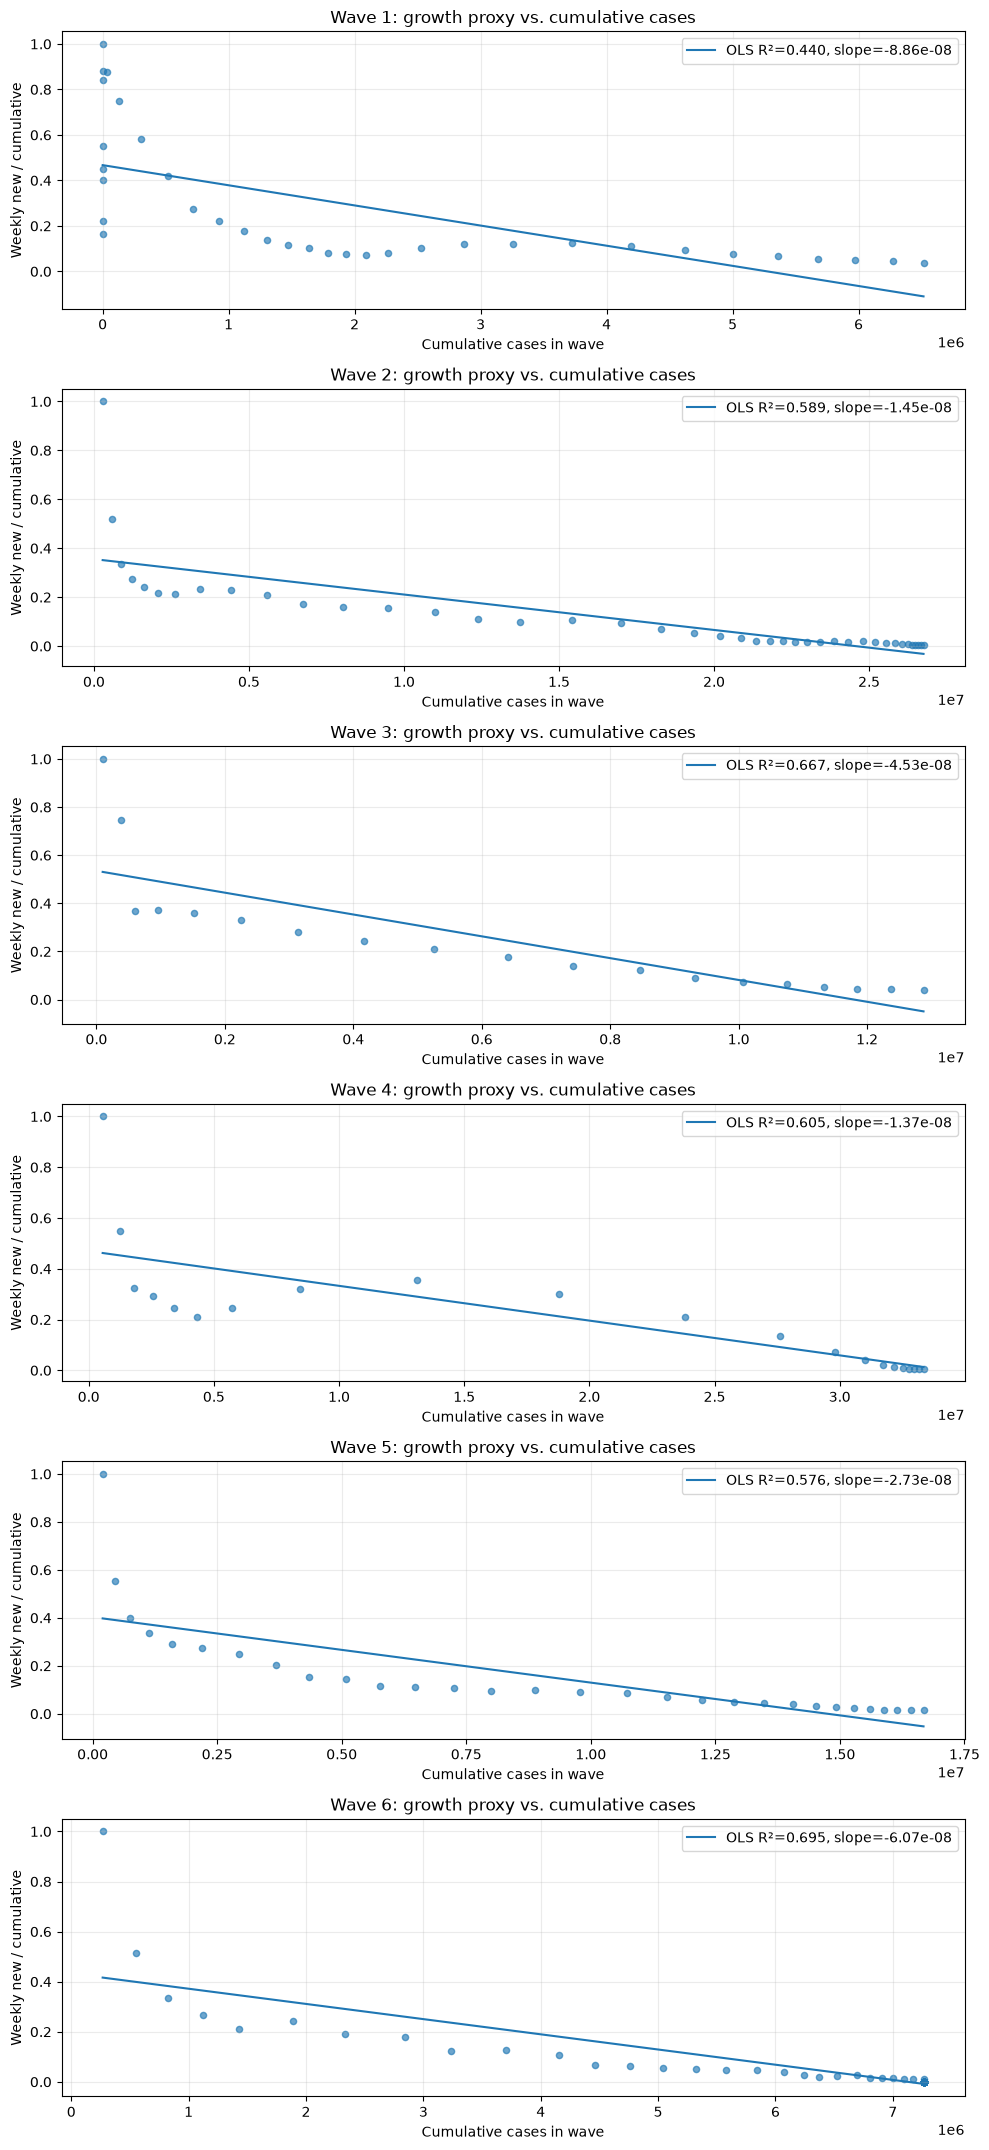

In [2]:
summary=[]
waves=sorted(df.wave.unique())

fig,axes=plt.subplots(len(waves),1,figsize=(10,3.6*len(waves)),squeeze=False)

for ax,w in zip(axes[:,0],waves):
    sub=df[df.wave==w]
    if len(sub)<3: continue
    fit=linregress(sub.cumulative_cases_in_wave,sub.growth_proxy)
    summary.append({"wave":int(w),"weeks":len(sub),"slope":fit.slope,"intercept":fit.intercept,"r_squared":fit.rvalue**2,"p_value":fit.pvalue})
    x=np.linspace(sub.cumulative_cases_in_wave.min(),sub.cumulative_cases_in_wave.max(),150)
    ax.scatter(sub.cumulative_cases_in_wave,sub.growth_proxy,s=20,alpha=.65)
    ax.plot(x,fit.intercept+fit.slope*x,label=f"OLS R²={fit.rvalue**2:.3f}, slope={fit.slope:.2e}")
    ax.set(title=f"Wave {w}: growth proxy vs. cumulative cases",xlabel="Cumulative cases in wave",ylabel="Weekly new / cumulative")
    ax.legend(); ax.grid(alpha=.25)

plt.tight_layout()

In [3]:
growth_summary=pd.DataFrame(summary)
growth_summary

,wave,weeks,slope,intercept,r_squared,p_value
0,1,34,-8.856304e-08,0.467255,0.439869,1.913853e-05
1,2,41,-1.447660e-08,0.355503,0.588698,4.871719e-09
2,3,19,-4.534965e-08,0.535005,0.667417,1.965621e-05
3,4,21,-1.369071e-08,0.469803,0.605400,3.286095e-05
4,5,30,-2.732143e-08,0.403084,0.576050,1.165629e-06
5,6,92,-6.069591e-08,0.432496,0.695297,5.955641e-25


## 2. Results and interpretation
A logistic model implies a declining per-capita growth rate as cumulative cases approach carrying capacity. A negative slope is consistent with that qualitative pattern, but a weak fit or positive slope indicates that a single logistic curve may not capture the wave's changing dynamics. Reporting changes, variants, behavior, immunity, and wave segmentation can all distort the proxy.

In [4]:
display(growth_summary.sort_values("wave"))

out=ROOT/"results/growth_rate_by_wave.csv"
out.parent.mkdir(parents=True,exist_ok=True)
growth_summary.to_csv(out,index=False)

print("Saved:",out)

,wave,weeks,slope,intercept,r_squared,p_value
0,1,34,-8.856304e-08,0.467255,0.439869,1.913853e-05
1,2,41,-1.447660e-08,0.355503,0.588698,4.871719e-09
2,3,19,-4.534965e-08,0.535005,0.667417,1.965621e-05
3,4,21,-1.369071e-08,0.469803,0.605400,3.286095e-05
4,5,30,-2.732143e-08,0.403084,0.576050,1.165629e-06
5,6,92,-6.069591e-08,0.432496,0.695297,5.955641e-25


Saved: c:\Users\tchin\Downloads\COVID19-Logistic-Growth-Project\results\growth_rate_by_wave.csv
